# Stock prediction: raw-return and rank-target training

Both completed experiments use the same sixteen candidates and full monthly cohorts. Only the learned training target changes. Evaluation uses all 94 common mature development months. The two final immature months remain in the tables and are excluded by the original maturity rule. No model is fitted in this notebook.

In [1]:
from pathlib import Path
import hashlib,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
pins = {'raw_return-metrics.json': 'a4ac02351747c5085b73a92d9e313b14b389b9b3c0b20ed00046bded7881af43', 'raw_return-development-selection.json': 'c7019b966fc707aadc68fae896dc67821b6e4673af2174fb3f5231e276e7a377', 'rank_target-metrics.json': '1cb8d23b1157879693bc01eaf0b050d998dbf9810de78d1e7e1f9994244a0dde', 'rank_target-development-selection.json': 'e6db2d817f03f9f330533a620ff39d7a38dd4743a499516200a014c71d19ed5c'}
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').exists())
report=root/'reports/stock_target_comparison_v1'
manifest=json.loads((report/'export-manifest.json').read_text())
assert (report/'COMPLETE').read_text().strip()==hashlib.sha256((report/'export-manifest.json').read_bytes()).hexdigest()
assert manifest['complete'] and not manifest['holdout_evaluated']
for name,digest in manifest['outputs_sha256'].items():
    assert hashlib.sha256((report/name).read_bytes()).hexdigest()==digest
for name,pin in pins.items():
    assert hashlib.sha256((report/name).read_bytes()).hexdigest() == pin
frames, selections = {}, {}
for label in ['raw_return','rank_target']:
    frames[label] = pd.DataFrame(json.loads((report/(label+'-metrics.json')).read_text()))
    selections[label] = json.loads((report/(label+'-development-selection.json')).read_text())
    assert len(frames[label]) == 1536
dates = selections['raw_return']['common_dates']
assert dates == selections['rank_target']['common_dates'] and len(dates)==94
wide = {label: frame[frame.signal_session.isin(dates)].pivot(index='signal_session',columns='candidate_id',values='ic').sort_index() for label,frame in frames.items()}
assert wide['raw_return'].index.equals(wide['rank_target'].index)
assert wide['raw_return'].columns.equals(wide['rank_target'].columns)
assert all(t.notna().all().all() for t in wide.values())
summary = pd.DataFrame({label:t.mean() for label,t in wide.items()})
summary['rank_minus_raw'] = summary.rank_target-summary.raw_return
controls = summary.index.str.startswith('control_')
np.testing.assert_array_equal(wide['raw_return'].loc[:,controls], wide['rank_target'].loc[:,controls])
display(summary.sort_values('raw_return',ascending=False))

,raw_return,rank_target,rank_minus_raw
candidate_id,,,
control_fixed_composite,0.023158,0.023158,0.000000
control_momentum_F01,0.018317,0.018317,0.000000
control_low_volatility_F09,0.009911,0.009911,0.000000
lgbm_regression_l1_leaves15_iterations100,0.008557,0.001598,-0.006959
lgbm_regression_l1_leaves15_iterations300,0.008072,0.001155,-0.006917
lgbm_regression_l1_leaves7_iterations100,0.004081,-0.003677,-0.007758
lgbm_regression_l1_leaves7_iterations300,0.003507,-0.000199,-0.003706
lgbm_regression_l2_leaves15_iterations300,-0.003420,0.006627,0.010047
lgbm_regression_l2_leaves7_iterations300,-0.007776,-0.000328,0.007448


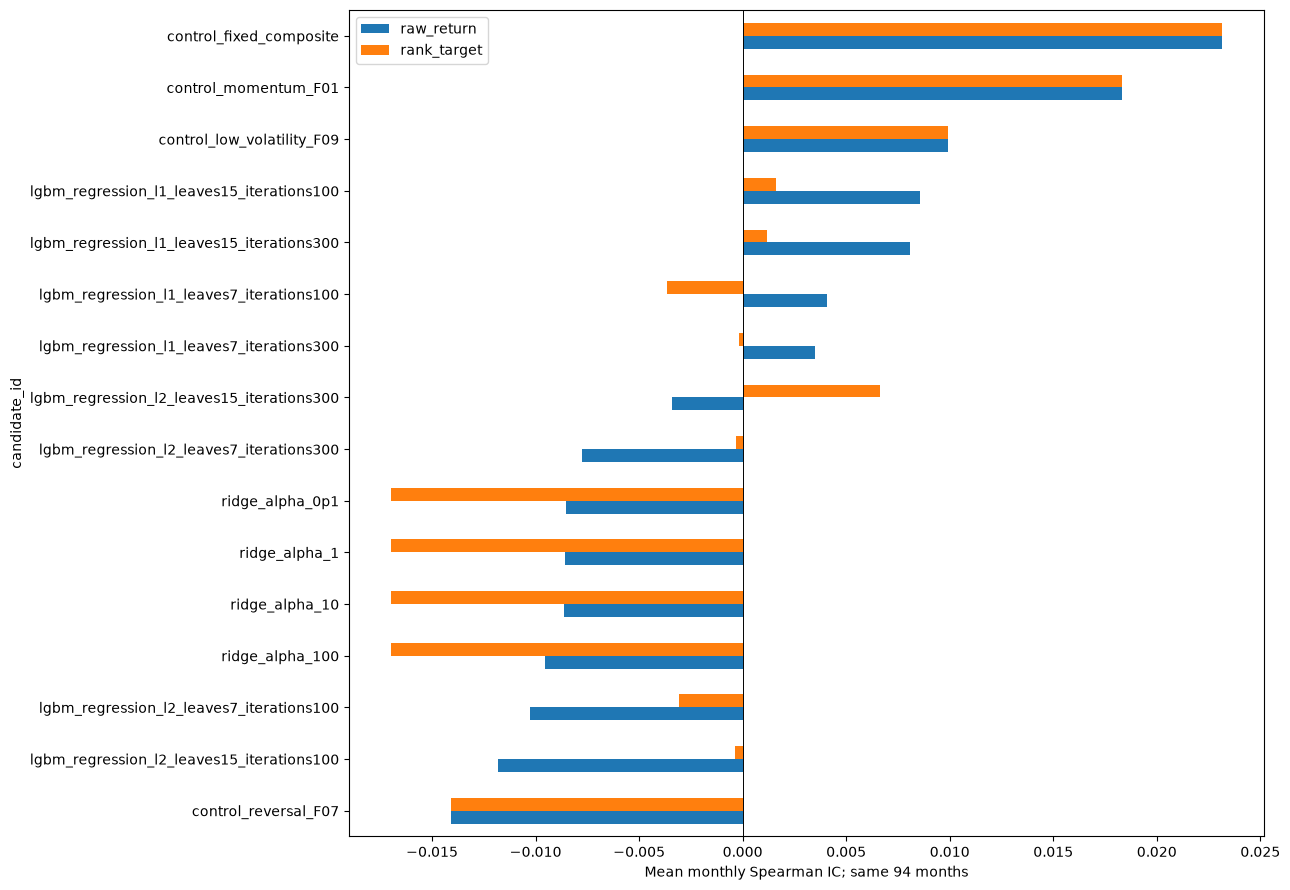

,candidate,block_months,mean_difference,lower,upper
0,control_fixed_composite,3,0.000000,0.000000,0.000000
1,control_low_volatility_F09,3,0.000000,0.000000,0.000000
2,control_momentum_F01,3,0.000000,0.000000,0.000000
3,control_reversal_F07,3,0.000000,0.000000,0.000000
4,lgbm_regression_l1_leaves15_iterations100,3,-0.006959,-0.016427,0.002167
5,lgbm_regression_l1_leaves15_iterations300,3,-0.006917,-0.016193,0.001908
6,lgbm_regression_l1_leaves7_iterations100,3,-0.007758,-0.017317,0.001265
7,lgbm_regression_l1_leaves7_iterations300,3,-0.003706,-0.014291,0.006307
8,lgbm_regression_l2_leaves15_iterations100,3,0.011458,0.000098,0.022871
9,lgbm_regression_l2_leaves15_iterations300,3,0.010047,-0.003629,0.023453


In [2]:
summary[['raw_return','rank_target']].sort_values('raw_return').plot.barh(figsize=(13,9))
plt.axvline(0,color='black',lw=.7)
plt.xlabel('Mean monthly Spearman IC; same 94 months')
plt.tight_layout()
plt.show()
differences = wide['rank_target']-wide['raw_return']
rng = np.random.default_rng(20261017)
records=[]
for block in [3,6,12]:
    starts=rng.integers(0,94,size=(2000,int(np.ceil(94/block))))
    index=((starts[:,:,None]+np.arange(block))%94).reshape(2000,-1)[:,:94]
    sampled=differences.to_numpy()[index].mean(axis=1)
    low,high=np.quantile(sampled,[.025,.975],axis=0)
    for j,name in enumerate(differences.columns):
        records.append(dict(candidate=name,block_months=block,mean_difference=differences[name].mean(),lower=low[j],upper=high[j]))
intervals=pd.DataFrame(records)
display(intervals.round(6))
pd.testing.assert_frame_equal(summary,pd.read_csv(report/'paired-target-summary.csv',index_col=0),check_exact=False,atol=1e-14,rtol=1e-12)
pd.testing.assert_frame_equal(intervals,pd.read_csv(report/'paired-target-intervals.csv'),check_exact=False,atol=1e-14,rtol=1e-12)

Intervals are descriptive development comparisons with unadjusted multiplicity. Observed months are resampled together for all candidates; no artificial market records are created. The fixed controls are identical across experiments. The rank-target experiment does not beat the best raw-return learned candidate or the fixed composite on mean IC. Portfolio economics and the registered feature ablation are separate evaluations; final-period outcomes remain sealed.